<a href="https://www.kaggle.com/code/sangeethakt/cookie-cats-a-b-test?scriptVersionId=371307172" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Cookie Cats A/B Test: Does Moving the First Gate from Level 30 to Level 40 Affect Retention?

**Question:** Cookie Cats is a mobile puzzle game. When the first progression gate was moved from level 30 to level 40, did player retention change? The test covers 90,189 players randomly assigned to either gate position.

**Result:** 7-day retention was lower with the gate at level 40 (18.20% vs 19.02%). The difference is 0.82 percentage points (95% CI +0.31 to +1.33, p = 0.0016), a relative drop of about 4.3%. 1-day retention showed no significant difference. The drop is concentrated among players who played 21 to 200 rounds.

**Recommendation:** Keep the first gate at level 30 and do not roll out level 40. Limitations: the group split was slightly uneven (p = 0.0086), the data has no revenue, and retention is only measured at days 1 and 7.

**Tools:** Python, pandas, statsmodels, matplotlib.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats/cookie_cats.csv


In [2]:
data=pd.read_csv("/kaggle/input/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats/cookie_cats.csv")

In [3]:
data.head(10)

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True
5,540,gate_40,187,True,True
6,1066,gate_30,0,False,False
7,1444,gate_40,2,False,False
8,1574,gate_40,108,True,True
9,1587,gate_40,153,True,False


In [4]:
df=pd.DataFrame(data)

In [5]:
df

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True
...,...,...,...,...,...
90184,9999441,gate_40,97,True,False
90185,9999479,gate_40,30,False,False
90186,9999710,gate_30,28,True,False
90187,9999768,gate_40,51,True,False


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [7]:
no_outlier = df[df.userid != 6390605]
print(df.groupby("version")["sum_gamerounds"].agg(["mean", "median"]))
print(no_outlier.groupby("version")["sum_gamerounds"].agg(["mean", "median"]))

              mean  median
version                   
gate_30  52.456264    17.0
gate_40  51.298776    16.0
              mean  median
version                   
gate_30  51.342111    17.0
gate_40  51.298776    16.0


In [8]:
print(df.userid.duplicated().sum())          # expect 0
print(df.version.value_counts())             # group sizes
print(df.sum_gamerounds.describe())          # look at the max
print(df.sort_values("sum_gamerounds", ascending=False).head())

0
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True


## 1. Data Overview and Quality Checks

**Dataset:** Cookie Cats A/B test (Kaggle), 90,189 players, 5 columns.

| Column | Type | Meaning |
|---|---|---|
| `userid` | int | Unique player ID |
| `version` | text | Test group: `gate_30` (control) or `gate_40` (variant) |
| `sum_gamerounds` | int | Game rounds played in the first 14 days |
| `retention_1` | bool | Player came back 1 day after install |
| `retention_7` | bool | Player came back 7 days after install |

### Checks

- **Missing values:** none. All columns have 90,189 non-null values.
- **Duplicate users:** 0, so each player appears once.

### Group sizes

| Group | Players | Share |
|---|---|---|
| `gate_30` (control) | 44,700 | 49.6% |
| `gate_40` (variant) | 45,489 | 50.4% |

The split is close to 50/50, but the groups differ by 789 players. A chi-square test for sample ratio mismatch is run in the next section.

### Outliers in `sum_gamerounds`

| Statistic | Value |
|---|---|
| Median | 16 |
| Mean | 51.9 |
| 75th percentile | 51 |
| Maximum | 49,854 |

The distribution is heavily right-skewed (mean far above the median). One player in `gate_30` (userid 6390605) played 49,854 rounds, about 17 times more than the next highest player (2,961). This is likely a bot, a tracking error or an extreme user.

**Handling:** retention is a yes/no metric, so this player has little effect on the retention test. The outlier does distort any analysis of game rounds, so game-round results are reported both with and without this player.

In [9]:
from scipy.stats import chisquare
print(chisquare(df["version"].value_counts()))

Power_divergenceResult(statistic=np.float64(6.9024049496058275), pvalue=np.float64(0.008607987810836262))


In [10]:
from scipy.stats import chisquare
print(chisquare([44700, 45489]))

Power_divergenceResult(statistic=np.float64(6.9024049496058275), pvalue=np.float64(0.008607987810836262))


### Sample ratio check

A chi-square test checks whether the group split is consistent with a fair 50/50 assignment.

| Statistic | p-value |
|---|---|
| 6.90 | 0.0086 |

The split is slightly uneven (49.6% vs 50.4%), and the difference is statistically significant at the 5% level. This could indicate a minor problem with how players were assigned to groups. The imbalance is small and falls above the stricter 0.001 threshold used by many experimentation teams, so the analysis continues, but the results below should be read with this caveat.

In [11]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

for metric in ["retention_1", "retention_7"]:
    g = df.groupby("version")[metric].agg(["sum", "count"])
    rate = g["sum"] / g["count"]
    stat, p = proportions_ztest(g["sum"], g["count"])
    low, high = confint_proportions_2indep(
        g.loc["gate_30", "sum"], g.loc["gate_30", "count"],
        g.loc["gate_40", "sum"], g.loc["gate_40", "count"])
    print(metric)
    print(rate)
    print("p-value:", p, "| 95% CI for gate_30 minus gate_40:", low, high)

retention_1
version
gate_30    0.448188
gate_40    0.442283
dtype: float64
p-value: 0.07440965529691913 | 95% CI for gate_30 minus gate_40: -0.000582095069752226 0.012391904992707325
retention_7
version
gate_30    0.190201
gate_40    0.182000
dtype: float64
p-value: 0.001554249975614329 | 95% CI for gate_30 minus gate_40: 0.00312130268876128 0.013281940871914845


## 2. Results

**Hypothesis:** Moving the first gate from level 30 to level 40 changes player retention.
**Primary metric:** 7-day retention. **Guardrail:** 1-day retention.
**Method:** two-proportion z-test, 95% confidence intervals for the difference.

| Metric | gate_30 | gate_40 | Difference (30 - 40) | 95% CI | p-value |
|---|---|---|---|---|---|
| 1-day retention | 44.82% | 44.23% | +0.59 pts | -0.06 to +1.24 pts | 0.074 |
| 7-day retention | 19.02% | 18.20% | +0.82 pts | +0.31 to +1.33 pts | 0.0016 |

- **1-day retention:** no statistically significant difference (the interval includes 0).
- **7-day retention:** gate_30 is significantly higher. gate_40 reduces 7-day retention by about 0.8 percentage points, a relative drop of about 4.3%. This holds after a Bonferroni correction for testing two metrics (threshold 0.025).

## 3. Recommendation

**Keep the first gate at level 30; do not roll out level 40.** Moving the gate later reduced 7-day retention, and the confidence interval rules out no effect. For every 100,000 new players, level 40 would be expected to retain roughly 300 to 1,300 fewer players after a week.

**Limitations:**
- The group split was slightly uneven (49.6% vs 50.4%, p = 0.0086), which may indicate a minor assignment issue.
- Only retention was tested here. Revenue, such as in-app purchases or ad views, isn't in the data, so a later gate could still affect revenue.
- Retention is measured at day 1 and day 7 only, so longer-term effects are unknown.

# 1. Retention rate by group with confidence intervals (the most important)


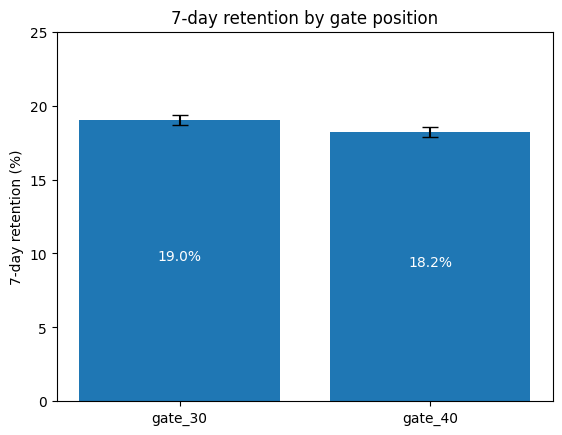

In [12]:
import matplotlib.pyplot as plt
import numpy as np

g = df.groupby("version")["retention_7"].agg(["mean", "count"])
se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])
bars = plt.bar(g.index, g["mean"] * 100, yerr=1.96 * se * 100, capsize=6)
for b, v in zip(bars, g["mean"] * 100):
    plt.text(b.get_x() + b.get_width() / 2, v / 2, f"{v:.1f}%", ha="center", color="white")
plt.ylim(0, 25)
plt.ylabel("7-day retention (%)")
plt.title("7-day retention by gate position")
plt.savefig("retention_by_gate.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Distribution of game rounds (log scale)


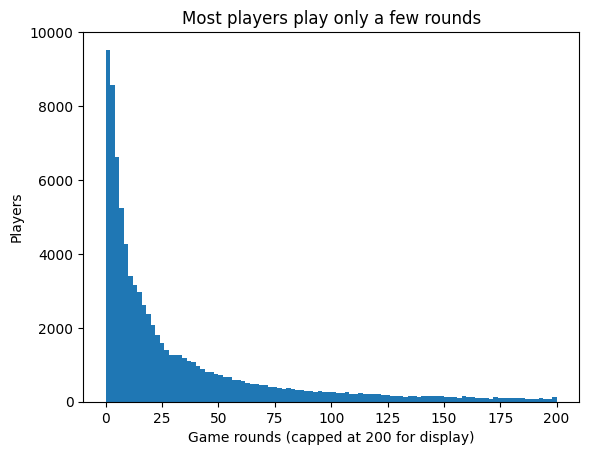

5223 players above 200 rounds not shown


In [13]:
import numpy as np
rounds = df["sum_gamerounds"]
plt.hist(rounds[rounds <= 200], bins=np.arange(0, 202, 2))
plt.xlabel("Game rounds (capped at 200 for display)")
plt.ylabel("Players")
plt.title("Most players play only a few rounds")
plt.savefig("game_rounds_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print((rounds > 200).sum(), "players above 200 rounds not shown")

In [14]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

bins = [-1, 5, 20, 50, 200, np.inf]
labels = ["0-5", "6-20", "21-50", "51-200", "200+"]
df["segment"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=labels)

rows = []
for seg, d in df.groupby("segment", observed=True):
    g = d.groupby("version")["retention_7"].agg(["sum", "count", "mean"])
    stat, p = proportions_ztest(g["sum"], g["count"])
    rows.append({"segment": seg,
                 "players": len(d),
                 "gate_30": g.loc["gate_30", "mean"],
                 "gate_40": g.loc["gate_40", "mean"],
                 "diff_30_minus_40": g.loc["gate_30", "mean"] - g.loc["gate_40", "mean"],
                 "p_value": p})
print(pd.DataFrame(rows))

  segment  players   gate_30   gate_40  diff_30_minus_40   p_value
0     0-5    24717  0.012193  0.013111         -0.000918  0.518804
1    6-20    25085  0.050290  0.047484          0.002806  0.302718
2   21-50    17575  0.160683  0.145615          0.015068  0.005606
3  51-200    17589  0.475794  0.447008          0.028786  0.000129
4    200+     5223  0.849136  0.850267         -0.001131  0.908942


## 4. Segment analysis (exploratory)

Players were grouped by total game rounds played in the first 14 days. 7-day retention was compared within each group (two-proportion z-test; Bonferroni-adjusted threshold 0.05 / 5 = 0.01).

| Segment (rounds) | Players | gate_30 | gate_40 | Difference (30 - 40) | p-value |
|---|---|---|---|---|---|
| 0-5 | 24,717 | 1.22% | 1.31% | -0.09 pts | 0.52 |
| 6-20 | 25,085 | 5.03% | 4.75% | +0.28 pts | 0.30 |
| 21-50 | 17,575 | 16.07% | 14.56% | +1.51 pts | 0.0056 |
| 51-200 | 17,589 | 47.58% | 44.70% | +2.88 pts | 0.0001 |
| 200+ | 5,223 | 84.91% | 85.03% | -0.11 pts | 0.91 |

**Finding:** the drop in 7-day retention from moving the gate to level 40 is concentrated among players who played 21-200 rounds (a relative drop of about 6-9%). Very light players (0-20 rounds) and very heavy players (200+) show no clear effect.

**Caveat:** segments are defined by rounds played after the gate was seen, so the gate may influence segment membership. These results are exploratory and should guide a follow-up test, not replace it.

In [15]:
res = pd.DataFrame(rows).set_index("segment"); 
print(res)

         players   gate_30   gate_40  diff_30_minus_40   p_value
segment                                                         
0-5        24717  0.012193  0.013111         -0.000918  0.518804
6-20       25085  0.050290  0.047484          0.002806  0.302718
21-50      17575  0.160683  0.145615          0.015068  0.005606
51-200     17589  0.475794  0.447008          0.028786  0.000129
200+        5223  0.849136  0.850267         -0.001131  0.908942


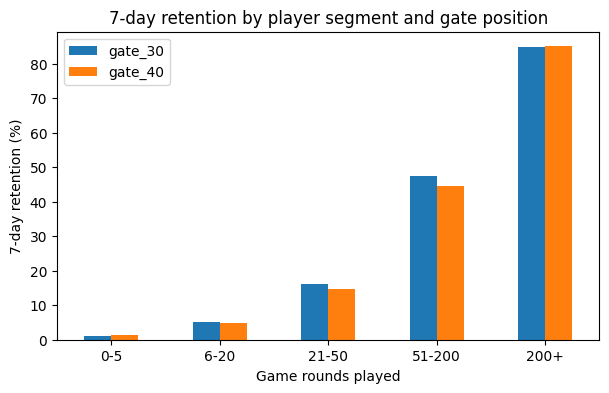

In [16]:
ax = (res[["gate_30", "gate_40"]] * 100).plot(kind="bar", rot=0, figsize=(7, 4))
ax.set_ylabel("7-day retention (%)")
ax.set_xlabel("Game rounds played")
ax.set_title("7-day retention by player segment and gate position")
plt.savefig("retention_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

effect = proportion_effectsize(0.195, 0.19)   # detect a 0.5-point difference
n = NormalIndPower().solve_power(effect, alpha=0.05, power=0.8, ratio=1)
print(round(n), "players per group needed")

97601 players per group needed


In [18]:

h = NormalIndPower().solve_power(nobs1=45000, alpha=0.05, power=0.8, ratio=1)
mde = np.sin(np.arcsin(np.sqrt(0.19)) + h / 2) ** 2 - 0.19
print(f"Minimum detectable difference: {mde*100:.2f} percentage points")

Minimum detectable difference: 0.74 percentage points


### Power and sample size

Detecting a 0.5-point difference in 7-day retention (19.0% vs 19.5%) at 80% power and a 5% significance level would need about 97,600 players per group. The experiment had about 45,000 per group, so it could reliably detect differences of about 0.74 percentage points or more.

The observed difference (0.82 points) is just above that threshold, so the experiment was large enough to detect it, but only just. A significant result from a test with limited power can overstate the true effect, and the confidence interval is wide (+0.31 to +1.33 points). The true effect may be smaller than 0.82 points, and a follow-up test with more players would give a more precise estimate.